In [1]:
import pickle, json, numpy as np

with open(r"D:\Resplan\ResPlan_clean.pkl", "rb") as f:
    plans = pickle.load(f)
images = np.load(r"D:\Resplan\resplan_64.npy")
split_json = json.load(open(r"D:\Resplan\split.json"))

ROOM_TYPES = ["living", "bedroom", "kitchen", "bathroom", "balcony", "storage", "stair", "front_door"]
T = {t: i for i, t in enumerate(ROOM_TYPES)}
EDGE_TYPES = ["via_door", "adjacency", "via_window", "direct"]     # 0 = not connected
E = {e: i + 1 for i, e in enumerate(EDGE_TYPES)}
TAGS = ["kitchen_in_living", "no_window", "no_front_door", "stair_overlap",
        "room_gaps", "shapes_repaired", "no_bedroom", "bad_area"]
SPLITS = ["train", "val", "test", "augmented"]
id_to_split = {pid: s for s, ids in split_json.items() for pid in ids}

N = len(plans)
MAXN = max(p["graph"].number_of_nodes() for p in plans)

node_type   = np.full((N, MAXN), -1, np.int8)            # -1 = empty slot
node_area   = np.zeros((N, MAXN), np.float32)            # share of total room area
room_box    = np.zeros((N, MAXN, 4), np.float32)         # centre x, centre y, width, height (0-1)
adjacency   = np.zeros((N, MAXN, MAXN), np.uint8)        # 0 none, 1 door, 2 open, 3 window, 4 entrance
relation    = np.zeros((N, len(ROOM_TYPES), len(ROOM_TYPES)), np.uint8)
room_counts = np.zeros((N, len(ROOM_TYPES)), np.uint8)

for i, p in enumerate(plans):
    G = p["graph"]
    x0, y0, x1, y1 = p["inner"].bounds
    s = max(x1 - x0, y1 - y0) or 1
    nodes = sorted(G.nodes, key=lambda n: (T.get(G.nodes[n].get("type"), 99), str(n)))
    pos = {n: k for k, n in enumerate(nodes)}
    total = sum(G.nodes[n].get("area", 0) for n in nodes) or 1

    for n in nodes:
        t = T.get(G.nodes[n].get("type"))
        if t is None:
            continue
        k = pos[n]
        node_type[i, k] = t
        node_area[i, k] = G.nodes[n].get("area", 0) / total
        room_counts[i, t] += 1
        g = G.nodes[n].get("geometry")
        if g is not None and not g.is_empty:
            a, b, c, e = g.bounds
            room_box[i, k] = [((a + c) / 2 - x0) / s, ((b + e) / 2 - y0) / s, (c - a) / s, (e - b) / s]

    for u, v, d in G.edges(data=True):
        e = E.get(d.get("type"), 0)
        adjacency[i, pos[u], pos[v]] = adjacency[i, pos[v], pos[u]] = e
        tu, tv = T.get(G.nodes[u].get("type")), T.get(G.nodes[v].get("type"))
        if tu is not None and tv is not None:
            relation[i, tu, tv] += 1
            if tu != tv:
                relation[i, tv, tu] += 1

area_m2 = np.array([p["area"] for p in plans], np.float32)   # NaN for the 6 bad_area plans
np.savez_compressed(
    r"D:\Resplan\resplan_tensors.npz",
    images=images,
    ids=np.array([p["id"] for p in plans], np.int64),
    split=np.array([SPLITS.index(id_to_split[p["id"]]) for p in plans], np.int8),
    area_m2=area_m2, area_sqft=area_m2 * 10.7639,
    bedrooms=room_counts[:, T["bedroom"]], bathrooms=room_counts[:, T["bathroom"]],
    room_counts=room_counts, relation=relation, adjacency=adjacency,
    node_type=node_type, node_area=node_area, room_box=room_box,
    tags=np.array([[t in p["tags"] for t in TAGS] for p in plans]),
    room_types=np.array(ROOM_TYPES), edge_types=np.array(["none"] + EDGE_TYPES),
    tag_names=np.array(TAGS), split_names=np.array(SPLITS),
)
print("Saved D:\\Resplan\\resplan_tensors.npz | plans:", N, "| max rooms per plan:", MAXN)

Saved D:\Resplan\resplan_tensors.npz | plans: 17000 | max rooms per plan: 23


In [2]:
import pandas as pd
d = np.load(r"D:\Resplan\resplan_tensors.npz")
for k in ["images", "room_counts", "relation", "adjacency", "node_type", "room_box", "area_sqft", "split"]:
    print(f"{k:12}", d[k].shape)

print("\nPlans per split:", dict(zip(d["split_names"], np.bincount(d["split"]))))

want_bed, want_sqft = 3, 1100
match = np.where((d["bedrooms"] == want_bed) &
                 (abs(d["area_sqft"] - want_sqft) <= 0.10 * want_sqft))[0]
print(f"\n{len(match)} plans match {want_bed} bedrooms, ~{want_sqft} sqft")

i = match[0]
print(f"\nRelationship matrix, plan #{i} ({d['area_sqft'][i]:.0f} sqft):")
print(pd.DataFrame(d["relation"][i], index=d["room_types"], columns=d["room_types"]))

images       (17000, 64, 64)
room_counts  (17000, 8)
relation     (17000, 8, 8)
adjacency    (17000, 23, 23)
node_type    (17000, 23)
room_box     (17000, 23, 4)
area_sqft    (17000,)
split        (17000,)

Plans per split: {np.str_('train'): np.int64(13053), np.str_('val'): np.int64(1632), np.str_('test'): np.int64(1632), np.str_('augmented'): np.int64(683)}

699 plans match 3 bedrooms, ~1100 sqft

Relationship matrix, plan #14 (1000 sqft):
            living  bedroom  kitchen  bathroom  balcony  storage  stair  \
living           0        3        1         1        1        0      0   
bedroom          3        2        1         3        1        0      0   
kitchen          1        1        0         0        0        0      0   
bathroom         1        3        0         0        0        0      0   
balcony          1        1        0         0        0        0      0   
storage          0        0        0         0        0        0      0   
stair            0        0  

## Part 1B: Circulation from the front door

In [3]:
d = np.load(r"D:\Resplan\resplan_tensors.npz")
adj, ntype = d["adjacency"], d["node_type"]
FRONT, BED, BATH = 7, 1, 3
WALK = [1, 4]          # walk through: 1 = door, 4 = front door. (2 = 'adjacency' is NOT walked)

N, M = ntype.shape
depth = np.full((N, M), -1, np.int8)          # -1 = not reached
passthrough = np.zeros(N, np.uint8)

for i in range(N):
    walk = np.isin(adj[i], WALK)
    start = np.where(ntype[i] == FRONT)[0]
    if len(start) == 0:
        continue
    parent = np.full(M, -1)
    depth[i, start] = 0
    queue = list(start)
    while queue:
        u = queue.pop(0)
        for v in np.where(walk[u] & (depth[i] == -1))[0]:
            depth[i, v] = depth[i, u] + 1
            parent[v] = u
            queue.append(v)
    for b in np.where(ntype[i] == BED)[0]:      # does the route to this bedroom cross a bedroom/bathroom?
        p = parent[b]
        while p >= 0 and ntype[i, p] != FRONT:
            if ntype[i, p] in (BED, BATH):
                passthrough[i] += 1
                break
            p = parent[p]

rooms = (ntype >= 0) & (ntype != FRONT)
reached = rooms & (depth > 0)
unreachable = (rooms & (depth == -1)).sum(1)
mean_depth = np.where(reached, depth, 0).sum(1) / np.maximum(reached.sum(1), 1)
max_depth = np.where(reached, depth, 0).max(1)
circulation_score = (rooms & (depth >= 1) & (depth <= 2)).sum(1) / np.maximum(rooms.sum(1), 1)

print("Plans with at least 1 room unreachable through doors:", int((unreachable > 0).sum()))
print("Plans with a bedroom reached through another bedroom/bathroom:", int((passthrough > 0).sum()))
print("Average depth (steps from front door):", np.round(np.percentile(mean_depth, [5, 50, 95]), 2), "(5%, median, 95%)")
print("Circulation score:", np.round(np.percentile(circulation_score, [5, 50, 95]), 2), "(5%, median, 95%)")

i = 14
print(f"\nExample, plan #{i}:")
for k in np.where(ntype[i] >= 0)[0]:
    print(f"  {d['room_types'][ntype[i, k]]:11} steps from entrance: {depth[i, k]}")

Plans with at least 1 room unreachable through doors: 5189
Plans with a bedroom reached through another bedroom/bathroom: 37
Average depth (steps from front door): [1.8  2.12 2.33] (5%, median, 95%)
Circulation score: [0.45 0.71 0.88] (5%, median, 95%)

Example, plan #14:
  living      steps from entrance: 1
  bedroom     steps from entrance: 2
  bedroom     steps from entrance: 2
  bedroom     steps from entrance: 2
  kitchen     steps from entrance: 2
  bathroom    steps from entrance: 2
  bathroom    steps from entrance: 3
  balcony     steps from entrance: 3
  balcony     steps from entrance: 2
  front_door  steps from entrance: 0


In [4]:
from collections import Counter

stuck, via = Counter(), Counter()
for i in np.where(unreachable > 0)[0]:
    for k in np.where(rooms[i] & (depth[i] == -1))[0]:
        t = d["room_types"][ntype[i, k]]
        stuck[t] += 1
        for j in np.where(adj[i, k] == 2)[0]:            # what is it 'adjacent' to?
            via[(t, d["room_types"][ntype[i, j]])] += 1

print("Unreachable rooms, by type:")
for t, n in stuck.most_common():
    print(f"  {t:10} {n}")
print("\nWhat those rooms are 'adjacent' to (top 10):")
for (a, b), n in via.most_common(10):
    print(f"  {a:10} <-> {b:10} {n}")

Unreachable rooms, by type:
  kitchen    3954
  bathroom   1480
  bedroom    1380
  balcony    897
  storage    844
  living     460
  stair      447

What those rooms are 'adjacent' to (top 10):
  kitchen    <-> living     3535
  kitchen    <-> bedroom    2002
  kitchen    <-> bathroom   1355
  storage    <-> living     757
  bathroom   <-> bedroom    635
  bedroom    <-> bathroom   622
  bedroom    <-> bedroom    557
  bathroom   <-> living     540
  bathroom   <-> bathroom   482
  storage    <-> bedroom    479


In [5]:
LIV, KIT = 0, 2

def walk_matrix(i):
    a = adj[i]
    w = np.isin(a, [1, 4])                                   # doors + front door
    t = ntype[i]
    open_lk = (a == 2) & (((t[:, None] == LIV) & (t[None, :] == KIT)) |
                          ((t[:, None] == KIT) & (t[None, :] == LIV)))
    return w | open_lk                                       # + open living <-> kitchen

depth = np.full((N, M), -1, np.int8)
passthrough = np.zeros(N, np.uint8)
for i in range(N):
    walk = walk_matrix(i)
    start = np.where(ntype[i] == FRONT)[0]
    if len(start) == 0:
        continue
    parent = np.full(M, -1)
    depth[i, start] = 0
    queue = list(start)
    while queue:
        u = queue.pop(0)
        for v in np.where(walk[u] & (depth[i] == -1))[0]:
            depth[i, v] = depth[i, u] + 1
            parent[v] = u
            queue.append(v)
    for b in np.where(ntype[i] == BED)[0]:
        p = parent[b]
        while p >= 0 and ntype[i, p] != FRONT:
            if ntype[i, p] in (BED, BATH):
                passthrough[i] += 1
                break
            p = parent[p]

reached = rooms & (depth > 0)
unreachable = (rooms & (depth == -1)).sum(1)
mean_depth = np.where(reached, depth, 0).sum(1) / np.maximum(reached.sum(1), 1)
max_depth = np.where(reached, depth, 0).max(1)
circulation_score = (rooms & (depth >= 1) & (depth <= 2)).sum(1) / np.maximum(rooms.sum(1), 1)
missing_door = unreachable > 0

np.savez_compressed(
    r"D:\Resplan\plan_features.npz",
    ids=d["ids"], depth=depth, mean_depth=mean_depth.astype(np.float32),
    max_depth=max_depth.astype(np.int8), unreachable=unreachable.astype(np.int8),
    bedroom_passthrough=passthrough, circulation_score=circulation_score.astype(np.float32),
    missing_door=missing_door,
)

stuck = Counter(d["room_types"][ntype[i, k]]
                for i in np.where(missing_door)[0]
                for k in np.where(rooms[i] & (depth[i] == -1))[0])
print("Plans with an unreachable room: before 5189 -> now", int(missing_door.sum()))
print("Still unreachable, by type:", dict(stuck.most_common()))
print("Circulation score:", np.round(np.percentile(circulation_score, [5, 50, 95]), 2), "(5%, median, 95%)")
print("Saved D:\\Resplan\\plan_features.npz")

Plans with an unreachable room: before 5189 -> now 2152
Still unreachable, by type: {np.str_('bathroom'): 1402, np.str_('bedroom'): 1309, np.str_('balcony'): 863, np.str_('storage'): 824, np.str_('living'): 456, np.str_('kitchen'): 455, np.str_('stair'): 440}
Circulation score: [0.5  0.71 0.89] (5%, median, 95%)
Saved D:\Resplan\plan_features.npz


### Finding: open kitchens and missing doors
- Walking only through doors left 5,189 plans with an unreachable room; 3,954 were kitchens,
  mostly next to the living room (open kitchens).
- **Decision:** circulation walks through doors, the front door, and open living↔kitchen connections only
  (not every 'adjacency', which also includes rooms that just share a wall).
- Rooms still unreachable are tagged `missing_door` (door not traced in the source drawing).
- Circulation score = share of rooms within 2 steps of the entrance.

## Part 1C: Daylight and cross-ventilation

In [6]:
HABITABLE = [0, 1, 2]      # living, bedroom, kitchen
WIN_H = 1.2                # assumed window height in metres

def parts(g):
    if g is None or g.is_empty:
        return []
    gs = list(g.geoms) if hasattr(g, "geoms") else [g]
    return [x for x in gs if x.geom_type == "Polygon" and not x.is_empty]

def side_bit(c, w):        # 1 right, 2 top, 4 left, 8 bottom (of the drawing)
    dx, dy = w.x - c.x, w.y - c.y
    if abs(dx) >= abs(dy):
        return 1 if dx > 0 else 4
    return 2 if dy > 0 else 8

areas = np.array([p["area"] for p in plans], dtype=float)
inner_areas = np.array([p["inner"].area for p in plans])
scales = np.sqrt(areas / inner_areas)                  # metres per drawing unit, per plan
scales[~np.isfinite(scales)] = np.nanmedian(scales)    # the 6 bad_area plans

window_ratio = np.zeros((N, M), np.float32)
window_sides = np.zeros((N, M), np.uint8)
flat_sides = np.zeros(N, np.uint8)

for i, p in enumerate(plans):
    G = p["graph"]
    wins = parts(p.get("window"))
    wd = float(p.get("wall_depth") or 4)
    sc = scales[i]
    fc = p["inner"].centroid
    for w in wins:
        flat_sides[i] |= side_bit(fc, w.centroid)
    nodes = sorted(G.nodes, key=lambda n: (T.get(G.nodes[n].get("type"), 99), str(n)))
    for k, n in enumerate(nodes):
        t = T.get(G.nodes[n].get("type"))
        g = G.nodes[n].get("geometry")
        if t is None or t == FRONT or g is None or g.is_empty or g.area == 0:
            continue
        near = g.buffer(wd * 0.75)
        c = g.centroid
        length, mask = 0.0, 0
        for w in wins:
            if w.intersects(near):
                x0, y0, x1, y1 = w.bounds
                length += max(x1 - x0, y1 - y0)
                mask |= side_bit(c, w.centroid)
        window_ratio[i, k] = (length * sc * WIN_H) / (g.area * sc * sc)
        window_sides[i, k] = mask

hab = np.isin(ntype, HABITABLE)
opposite = ((window_sides & 5) == 5) | ((window_sides & 10) == 10)
dark_rooms = (hab & (window_sides == 0)).sum(1)
daylight_score = (hab & (window_ratio >= 0.10)).sum(1) / np.maximum(hab.sum(1), 1)
cross_vent_rooms = (hab & opposite).sum(1)
cross_vent_flat = ((flat_sides & 5) == 5) | ((flat_sides & 10) == 10)

f = dict(np.load(r"D:\Resplan\plan_features.npz"))
f.update(window_ratio=window_ratio, window_sides=window_sides,
         dark_rooms=dark_rooms.astype(np.int8), daylight_score=daylight_score.astype(np.float32),
         cross_vent_rooms=cross_vent_rooms.astype(np.int8), cross_vent_flat=cross_vent_flat)
np.savez_compressed(r"D:\Resplan\plan_features.npz", **f)

wr = window_ratio[hab & (window_sides > 0)]
print("Window ratio of rooms with windows:", np.round(np.percentile(wr, [5, 50, 95]), 3), "(5%, median, 95%)")
print("Plans with at least 1 dark room:", int((dark_rooms > 0).sum()))
print("Daylight score:", np.round(np.percentile(daylight_score, [5, 50, 95]), 2), "(5%, median, 95%)")
print("Plans with at least 1 cross-ventilated room:", int((cross_vent_rooms > 0).sum()))
print("Flats with windows on opposite sides:", int(cross_vent_flat.sum()))

i = 14
print(f"\nExample, plan #{i}:")
names = {1: "right", 2: "top", 4: "left", 8: "bottom"}
for k in np.where(hab[i])[0]:
    sides = [v for b, v in names.items() if window_sides[i, k] & b] or ["none"]
    print(f"  {d['room_types'][ntype[i, k]]:9} window ratio {window_ratio[i, k]:.2f} | windows: {', '.join(sides)}")
print("Saved D:\\Resplan\\plan_features.npz")

Window ratio of rooms with windows: [0.049 0.132 0.299] (5%, median, 95%)
Plans with at least 1 dark room: 6589
Daylight score: [0.2 0.6 1. ] (5%, median, 95%)
Plans with at least 1 cross-ventilated room: 4640
Flats with windows on opposite sides: 15807

Example, plan #14:
  living    window ratio 0.06 | windows: top, bottom
  bedroom   window ratio 0.18 | windows: right, left
  bedroom   window ratio 0.00 | windows: none
  bedroom   window ratio 0.19 | windows: top
  kitchen   window ratio 0.13 | windows: top
Saved D:\Resplan\plan_features.npz


In [7]:
BAL = 4
dark = hab & (window_sides == 0)
touches_balcony = np.zeros_like(dark)
for i in np.where(dark.any(1))[0]:
    for k in np.where(dark[i])[0]:
        touches_balcony[i, k] = (ntype[i][adj[i, k] > 0] == BAL).any()

print("Dark living/bedroom/kitchen rooms:", int(dark.sum()))
print("  ...of which open onto a balcony:", int(touches_balcony.sum()))
print("Plans with a TRULY dark room (no window, no balcony):",
      int((dark & ~touches_balcony).any(1).sum()))

Dark living/bedroom/kitchen rooms: 10243
  ...of which open onto a balcony: 7563
Plans with a TRULY dark room (no window, no balcony): 2138


In [8]:
balcony_lit = touches_balcony                        # rooms lit through a balcony door
truly_dark = (dark & ~balcony_lit).sum(1)
daylight_score_v2 = (hab & ((window_ratio >= 0.10) | balcony_lit)).sum(1) / np.maximum(hab.sum(1), 1)

f = dict(np.load(r"D:\Resplan\plan_features.npz"))
f.update(balcony_lit=balcony_lit, dark_rooms=truly_dark.astype(np.int8),
         daylight_score=daylight_score_v2.astype(np.float32))
np.savez_compressed(r"D:\Resplan\plan_features.npz", **f)

print("Daylight score:", np.round(np.percentile(daylight_score_v2, [5, 50, 95]), 2), "(5%, median, 95%)")
print("Saved. Keys:", sorted(f.keys()))

Daylight score: [0.25 0.75 1.  ] (5%, median, 95%)
Saved. Keys: ['balcony_lit', 'bedroom_passthrough', 'circulation_score', 'cross_vent_flat', 'cross_vent_rooms', 'dark_rooms', 'daylight_score', 'depth', 'ids', 'max_depth', 'mean_depth', 'missing_door', 'unreachable', 'window_ratio', 'window_sides']


### Finding: daylight and ventilation
- Window ratio = window area ÷ floor area (window height assumed 1.2 m); median 0.13,
  so the typical room meets the 10% rule of thumb.
- 10,243 living/bedroom/kitchen rooms have no window, but 74% of them open onto a balcony
  (borrowed light, common in South Asian flats). These are flagged `balcony_lit` and count as lit.
- Truly dark rooms (no window, no balcony): 2,138 plans (13%).
- Cross-ventilation = windows on opposite walls of a room; 4,640 plans have at least one such room.
  "Windows on opposite sides of the flat" is true for 93% of plans, so it is not used.
- No north direction exists in the data, so "sides" are sides of the drawing, not orientation.

## Part 1D: One PNG per plan for the website

In [3]:
import pickle, numpy as np

with open(r"D:\Resplan\ResPlan_clean.pkl", "rb") as f:
    plans = pickle.load(f)
d = np.load(r"D:\Resplan\resplan_tensors.npz")

def parts(g):
    if g is None or g.is_empty:
        return []
    gs = list(g.geoms) if hasattr(g, "geoms") else [g]
    return [x for x in gs if x.geom_type == "Polygon" and not x.is_empty]

print("Reloaded", len(plans), "plans")

Reloaded 17000 plans


In [4]:
import os, cv2
from tqdm import tqdm

OUT = r"D:\Resplan\plans_png"
os.makedirs(OUT, exist_ok=True)
SIZE, PAD = 256, 8

DRAW = [("living", "#f4b183"), ("bedroom", "#9dc3e6"), ("kitchen", "#ffd966"),
        ("bathroom", "#a9d18e"), ("balcony", "#d5a6bd"), ("storage", "#bfbfbf"),
        ("stair", "#8e7cc3"), ("wall", "#222222"), ("door", "#c55a11"),
        ("window", "#2e75b6"), ("front_door", "#ff0000")]
BGR = {k: tuple(int(c[j:j + 2], 16) for j in (5, 3, 1)) for k, c in DRAW}

def render_png(p):
    layers = {k: parts(p.get(k)) for k, _ in DRAW}
    allp = [q for v in layers.values() for q in v]
    img = np.full((SIZE, SIZE, 3), 255, np.uint8)
    if not allp:
        return img
    minx = min(q.bounds[0] for q in allp); miny = min(q.bounds[1] for q in allp)
    maxx = max(q.bounds[2] for q in allp); maxy = max(q.bounds[3] for q in allp)
    s = (SIZE - 2 * PAD) / max(maxx - minx, maxy - miny)
    ox = (SIZE - (maxx - minx) * s) / 2
    oy = (SIZE - (maxy - miny) * s) / 2
    def px(coords):
        c = np.asarray(coords)
        return np.round(np.stack([(c[:, 0] - minx) * s + ox,
                                  (maxy - c[:, 1]) * s + oy], 1)).astype(np.int32)
    for k, _ in DRAW:
        for q in layers[k]:
            m = np.zeros((SIZE, SIZE), np.uint8)
            cv2.fillPoly(m, [px(q.exterior.coords)], 1)
            for h in q.interiors:
                cv2.fillPoly(m, [px(h.coords)], 0)
            img[m == 1] = BGR[k]
    return img

for p in tqdm(plans):
    cv2.imwrite(os.path.join(OUT, f"{p['id']}.png"), render_png(p))

files = os.listdir(OUT)
size_mb = sum(os.path.getsize(os.path.join(OUT, f)) for f in files) / 1e6
print(f"Saved {len(files)} PNGs to {OUT} ({size_mb:.0f} MB)")

100%|██████████| 17000/17000 [01:16<00:00, 222.95it/s]


Saved 17000 PNGs to D:\Resplan\plans_png (111 MB)


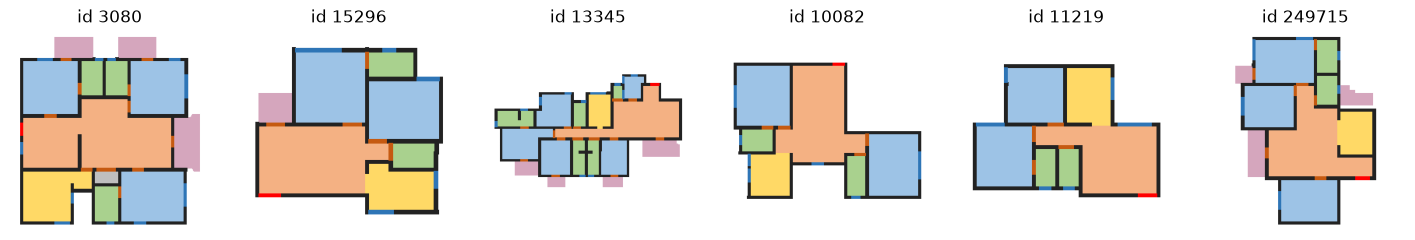

In [5]:
import matplotlib.pyplot as plt, random
pick = random.sample(list(d["ids"]), 6)
fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
for ax, pid in zip(axes, pick):
    ax.imshow(cv2.imread(os.path.join(OUT, f"{pid}.png"))[:, :, ::-1])
    ax.set_title(f"id {pid}"); ax.axis("off")
plt.show()

In [1]:
import numpy as np, os

d = np.load(r"D:\Resplan\resplan_tensors.npz")
f = np.load(r"D:\Resplan\plan_features.npz")

keep = d["split"] != 3            # leave out the 683 augmented copies
os.makedirs(r"..\..\02_model_server", exist_ok=True)
out = r"..\..\02_model_server\search_index.npz"

np.savez_compressed(out,
    ids=d["ids"][keep], bedrooms=d["bedrooms"][keep], bathrooms=d["bathrooms"][keep],
    area_sqft=d["area_sqft"][keep], room_counts=d["room_counts"][keep], relation=d["relation"][keep],
    circulation_score=f["circulation_score"][keep], daylight_score=f["daylight_score"][keep],
    cross_vent_rooms=f["cross_vent_rooms"][keep], dark_rooms=f["dark_rooms"][keep],
    missing_door=f["missing_door"][keep], room_types=d["room_types"])
print("Saved", out, f"({os.path.getsize(out)/1e6:.1f} MB), plans:", keep.sum())

Saved ..\..\02_model_server\search_index.npz (0.3 MB), plans: 16317
